In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import starbars

### 1. Import imaging analysis data from Excel

In [20]:
dataarea = pd.read_excel("./Data/sialidase_20241004_mask_overlap_summary.xlsx",skiprows=[1],index_col=0,usecols=[0,2,5],nrows=181)
dataarea.tail()
dataarea.columns = ["FileName","Area"]
#dataarea.shape

In [12]:
dataarea = pd.read_excel("./Data/sialidase_20241004_mask_overlap_summary.xlsx",sheet_name="Sheet2",skiprows=[0],usecols=[0,1,2],nrows=52)
dataarea.tail()

,Ctrl T cells,sec-Sialidase T cells,TM-Sialidase T cells
46,8.529048,36.429228,10.519740
47,35.052732,NaN,83.413044
48,35.196480,NaN,1.973268
49,31.768308,NaN,2.086524
50,3.267000,NaN,NaN


In [3]:
datatime = pd.read_excel("./Data/20240731 manual count.xlsx",sheet_name="ova analysis",skiprows=[1],index_col=0,usecols=[6,7,8,9],nrows=43)
datatime.columns = ["WT","Tmem165","Slc35a2"]
datatime.head()

,WT,Tmem165,Slc35a2
Total touch time,,,
Cell 1,2396.8,338.0,1384.0
Cell 2,2054.4,929.5,778.5
Cell 3,8217.6,9802.0,778.5
Cell 4,12668.8,5577.0,7093.0
Cell 5,14637.6,25857.0,6401.0


In [4]:
np.mean(datatime,axis=0)

WT         7791.590698
Tmem165    8791.930233
Slc35a2    6559.918605
dtype: float64

In [85]:
dataavg = pd.read_excel("./Data/20240731 manual count.xlsx",sheet_name="ova analysis",skiprows=[1],index_col=0,usecols=[12,13,14,15],nrows=43)
dataavg.columns = ["WT","Tmem165","Slc35a2"]
dataavg.head()

,WT,Tmem165,Slc35a2
ave time/touch (per cell),,,
Cell 1,1079.937500,1723.600000,2407.693333
Cell 2,1267.571429,932.480000,774.620000
Cell 3,980.700000,231.466667,1391.633333
Cell 4,747.200000,218.240000,273.855556
Cell 5,575.966667,3117.714286,1207.200000


In [5]:
datatimes = pd.read_excel("./Data/20240731 manual count.xlsx",sheet_name="ova analysis",skiprows=[1],usecols=[18,19,20])
datatimes.columns = ["WT","Tmem165","Slc35a2"]
datatimes.head()

,WT,Tmem165,Slc35a2
0,2396.8,338.0,1384.0
1,599.2,760.5,519.0
2,1455.2,169.0,259.5
3,8217.6,5070.0,259.5
4,1284.0,4732.0,519.0


In [3]:
datadeath = pd.read_excel("./Data/20240731 manual count.xlsx",sheet_name="ova analysis",skiprows=[1],index_col=0,usecols=[26,27,28,29],nrows=43)
datadeath.columns = ["WT.1","Tmem165.1","Slc35a2.1"]
datadeath.head()

,WT.1,Tmem165.1,Slc35a2.1
Death,,,
Cell 1,40.0,13.0,21.0
Cell 2,45.0,13.0,21.0
Cell 3,NaN,86.0,23.0
Cell 4,86.0,NaN,54.0
Cell 5,NaN,98.0,NaN


### 2. Analyze data and make plots

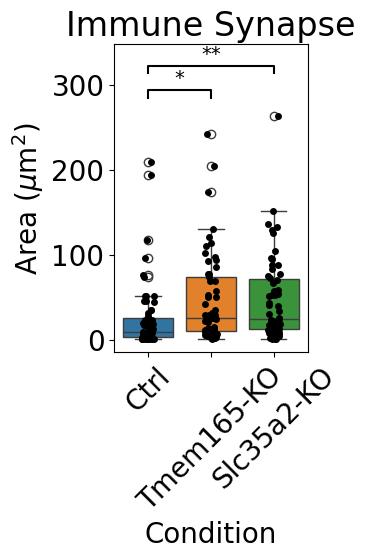

In [26]:
# Synapse area
t1 = stats.ttest_ind(dataarea.loc["Ctrl","Area"], dataarea.loc["Tmem165-KO","Area"],equal_var=False)
t2 = stats.ttest_ind(dataarea.loc["Ctrl","Area"], dataarea.loc["Slc35a2-KO","Area"],equal_var=False)
# Number of touches per cell
plt.rcParams['font.size'] = 20
fig, ax = plt.subplots(figsize=(2.5,4))
ax = sns.boxplot(x="Condition",y="Area",hue="Condition",data=dataarea)
ax = sns.stripplot(x="Condition",y="Area",data=dataarea,color="k")
annotations = [("Ctrl", "Tmem165-KO", t1.pvalue), ("Ctrl", "Slc35a2-KO", t2.pvalue)]
starbars.draw_annotation(annotations,fontsize=14,top_margin=0.05)
plt.xticks(rotation=45)
plt.title("Immune Synapse")
plt.ylabel(r"Area ($\mu$m$^2$)")
plt.savefig('Plots/Immune_Synapse_Area.pdf',bbox_inches='tight')
plt.show()

In [13]:
t1 = stats.ttest_ind(dataarea.loc["Ctrl","Area"], dataarea.loc["Tmem165-KO","Area"],equal_var=False)
t2 = stats.ttest_ind(dataarea.loc["Ctrl","Area"], dataarea.loc["Slc35a2-KO","Area"],equal_var=False)
t1

TtestResult(statistic=-2.6049289757014495, pvalue=0.010561422491479708, df=102.0560689341385)

In [16]:
dataarea.iloc[0:51,0]

0       7.562016
1       4.408272
2      90.983772
3      15.895044
4      10.044936
5      26.131644
6      18.639324
7       8.315604
8      20.116008
9      12.013848
10     25.147188
11      6.359760
12      3.162456
13     19.754460
14      2.352240
15      2.090880
16     39.295476
17     76.804992
18     16.757532
19     24.641892
20     22.459536
21      8.794764
22     14.344308
23    109.888812
24      1.794672
25      1.128204
26      2.700720
27     59.733828
28      3.036132
29      2.265120
30      3.798432
31      1.058508
32    184.929624
33     50.085288
34     71.312076
35     32.434776
36      0.888624
37      1.163052
38      0.888624
39     10.145124
40     34.333992
41     10.685268
42    117.280944
43      6.738732
44     18.665460
45      0.270072
46      8.529048
47     35.052732
48     35.196480
49     31.768308
50      3.267000
Name: Ctrl T cells, dtype: float64

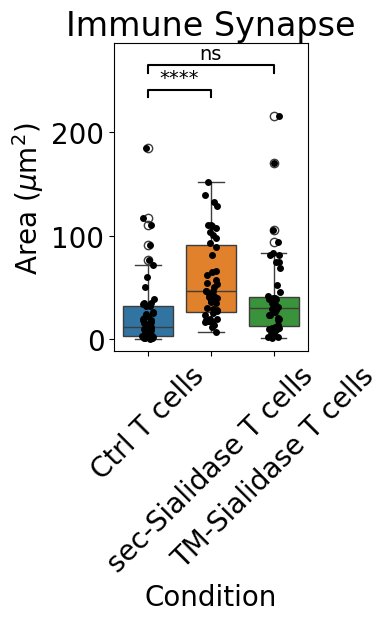

In [17]:
t1 = stats.ttest_ind(dataarea.iloc[:,0], dataarea.iloc[0:47,1],equal_var=False)
t2 = stats.ttest_ind(dataarea.iloc[:,0], dataarea.iloc[0:50,2],equal_var=False)
# Number of touches per cell
dfarea = pd.melt(dataarea,var_name="Condition",value_name="Area")
dfarea.head()
plt.rcParams['font.size'] = 20
fig, ax = plt.subplots(figsize=(2.5,4))
ax = sns.boxplot(x="Condition",y="Area",hue="Condition",data=dfarea)
ax = sns.stripplot(x="Condition",y="Area",data=dfarea,color="k")
annotations = [("Ctrl T cells", "sec-Sialidase T cells", t1.pvalue), ("Ctrl T cells", "TM-Sialidase T cells", t2.pvalue)]
starbars.draw_annotation(annotations,fontsize=14,top_margin=0.05)
plt.xticks(rotation=45)
plt.title("Immune Synapse")
plt.ylabel(r"Area ($\mu$m$^2$)")
plt.savefig('Plots/Immune_Synapse_Area_sialidase.pdf',bbox_inches='tight')
plt.show()

In [18]:
t1.pvalue, t2.pvalue

(7.634184490375517e-05, 0.06775205278176288)

In [63]:
# Plot total touching time per cell
def plot_compare(data,ylab,fname):
    t1 = stats.ttest_ind(data.loc[:,"WT"], data.loc[:,"Tmem165"],equal_var=False) # Statistical comparisons
    t2 = stats.ttest_ind(data.loc[:,"WT"], data.loc[:,"Slc35a2"],equal_var=False)
    df = pd.melt(data,var_name="Condition",value_name="touches")
    plt.rcParams['font.size'] = 20
    fig, ax = plt.subplots(figsize=(2.5,4))
    ax = sns.boxplot(x="Condition",y="touches",hue="Condition",data=df)
    ax = sns.stripplot(x="Condition",y="touches",data=df,color="k")
    annotations = [("WT", "Tmem165", t1.pvalue), ("WT", "Slc35a2", t2.pvalue)]
    starbars.draw_annotation(annotations,fontsize=14,top_margin=0.05) # Add significance annotations
    plt.xticks(rotation=45)
    plt.ylabel(ylab)
    plt.savefig(fname,bbox_inches='tight') # Save plot
    plt.show()
    return([t1,t2])

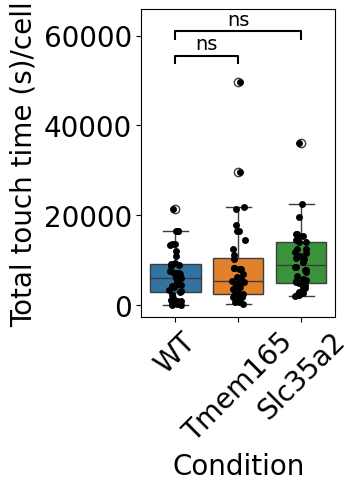

[TtestResult(statistic=nan, pvalue=nan, df=nan),
 TtestResult(statistic=nan, pvalue=nan, df=nan)]

In [87]:
plot_compare(datatime,"Total touch time (s)/cell","Plots/Total_touch_time.pdf")

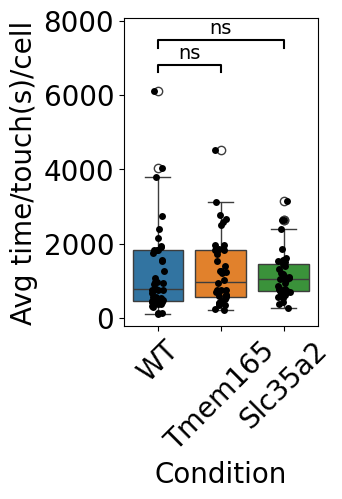

[TtestResult(statistic=nan, pvalue=nan, df=nan),
 TtestResult(statistic=nan, pvalue=nan, df=nan)]

In [88]:
# Average touch time
plot_compare(dataavg,"Avg time/touch(s)/cell","Plots/Average_touch_time.pdf")

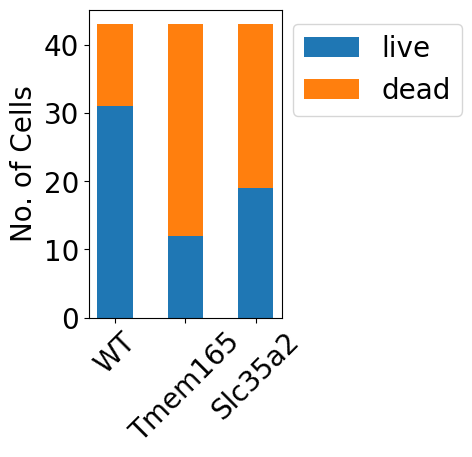

In [69]:
# Plot dead/total cells
dead = np.array([12,31,24])
live = 43-dead
df = pd.DataFrame({'Condition':["WT","Tmem165","Slc35a2"],'dead':dead,'live':live})
plt.rcParams['font.size'] = 20
fig, ax = plt.subplots(figsize=(2.5,4))
ax.bar(df['Condition'], df['live'],label='live',width=0.5)
ax.bar(df['Condition'], df['dead'],bottom=df.live,label='dead',width=0.5)
plt.legend(loc='upper right', bbox_to_anchor=(2, 1))
plt.xticks(rotation=45)
plt.ylabel("No. of Cells")
plt.savefig('Plots/Death_summary.pdf',bbox_inches='tight')
plt.show()

### 3. Analysis using bootstrapping

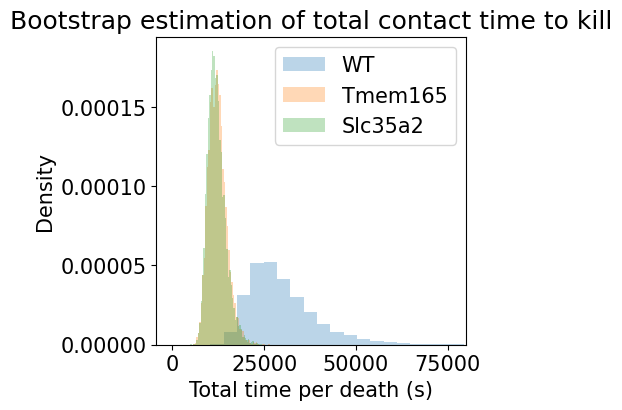

In [4]:
# Chance of death for each touch (# touches/# deaths), table datatouch
df = pd.concat([datatime,datadeath],axis=1)
n = 10000
c = df.shape[0]
deatht = np.zeros(shape=(n,3))
for t in range(n):
    wt = df[["WT","WT.1"]].sample(n=c,replace=True)
    tmem = df[["Tmem165","Tmem165.1"]].sample(n=c,replace=True)
    slc = df[['Slc35a2','Slc35a2.1']].sample(n=c,replace=True)
    # Get how many death per sample, calculate total deaths/total touches
    deatht[t,0] = wt.iloc[:,0].sum()/(np.isnan(wt.iloc[:,1])==False).sum()
    deatht[t,1] = tmem.iloc[:,0].sum()/(np.isnan(tmem.iloc[:,1])==False).sum()
    deatht[t,2] = slc.iloc[:,0].sum()/(np.isnan(slc.iloc[:,1])==False).sum()
deatht = pd.DataFrame(deatht,columns=["WT","Tmem165","Slc35a2"])
plt.rcParams['font.size'] = 15
fig, ax = plt.subplots(figsize=(4,4))
ax.hist(deatht["WT"], label="WT",alpha=0.3,bins=50,density=True)
ax.hist(deatht["Tmem165"],label="Tmem165",alpha=0.3,bins=50,density=True)
ax.hist(deatht["Slc35a2"],label="Slc35a2",alpha=0.3,bins=50,density=True)
plt.xlim(right=80000)
plt.xlabel("Total time per death (s)")
plt.ylabel("Density")
plt.title("Bootstrap estimation of total contact time to kill")
plt.legend(loc='upper right')
plt.savefig('Plots/Total_contact_bootstrap.pdf',bbox_inches="tight")
plt.show()

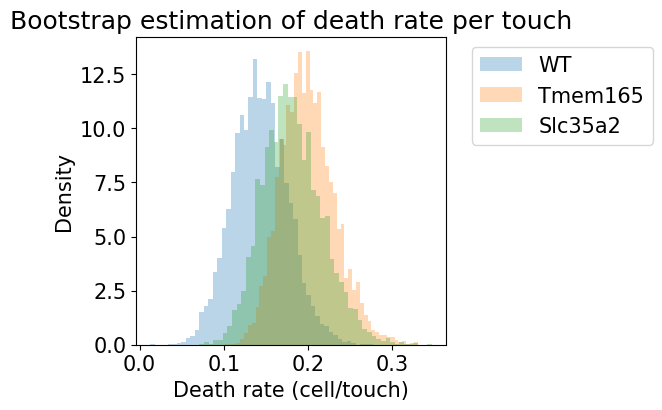

In [82]:
# Chance of death for each touch (# touches/# deaths), table datatouch
df = pd.concat([datatouch,datadeath],axis=1)
n = 10000
c = df.shape[0]
deatht = np.zeros(shape=(n,3))
for t in range(n):
    wt = df[["WT","WT.1"]].sample(n=c,replace=True)
    tmem = df[["Tmem165","Tmem165.1"]].sample(n=c,replace=True)
    slc = df[['Slc35a2','Slc35a2.1']].sample(n=c,replace=True)
    # Get how many death per sample, calculate total deaths/total touches
    deatht[t,0] = (np.isnan(wt.iloc[:,1])==False).sum()/wt.iloc[:,0].sum()
    deatht[t,1] = (np.isnan(tmem.iloc[:,1])==False).sum()/tmem.iloc[:,0].sum()
    deatht[t,2] = (np.isnan(slc.iloc[:,1])==False).sum()/slc.iloc[:,0].sum()
deatht = pd.DataFrame(deatht,columns=["WT","Tmem165","Slc35a2"])
plt.rcParams['font.size'] = 15
fig, ax = plt.subplots(figsize=(4,4))
ax.hist(deatht["WT"], label="WT",alpha=0.3,bins=50,density=True)
ax.hist(deatht["Tmem165"],label="Tmem165",alpha=0.3,bins=50,density=True)
ax.hist(deatht["Slc35a2"],label="Slc35a2",alpha=0.3,bins=50,density=True)
plt.xlabel("Death rate (cell/touch)")
plt.ylabel("Density")
plt.title("Bootstrap estimation of death rate per touch")
plt.legend(loc='upper right',bbox_to_anchor=(1.7, 1))
plt.savefig('Plots/Death_rate_bootstrap.pdf',bbox_inches="tight")
plt.show()

In [6]:
# Calculate difference
mean = deatht.mean(axis=0)
median = deatht.median(axis=0)
se = deatht.std()
print(mean)
print(median)
print(se)

WT         30204.714291
Tmem165    12338.314798
Slc35a2    12055.209219
dtype: float64
WT         28019.334266
Tmem165    12131.207292
Slc35a2    11723.581845
dtype: float64
WT         10496.938011
Tmem165     2470.558536
Slc35a2     2447.324673
dtype: float64


In [8]:
df.sum(axis=0)

WT           335038.4
Tmem165      378053.0
Slc35a2      282076.5
WT.1            807.0
Tmem165.1      1799.0
Slc35a2.1      1284.0
dtype: float64

In [9]:
print(335038.4/12)
print(378053.0/31)
print(282076.5/24)

27919.86666666667
12195.258064516129
11753.1875


In [89]:
t1 = ((deathr["WT"]-deathr["Tmem165"])>0).sum()/10000
t2 = ((deathr["WT"]-deathr["Slc35a2"])>0).sum()/10000
print(t1,t2)

0.0975 0.2067


In [102]:
t1 = ((deatht["WT"]-deatht["Tmem165"])<0).sum()/100000
t2 = ((deatht["WT"]-deatht["Slc35a2"])<0).sum()/100000
print(t1,t2)

0.00428 0.00348


In [51]:
df = pd.concat([datatouch,datadeath],axis=1)
df[["WT","WT.1"]].head()

,WT,WT.1
Cell 1,1,40.0
Cell 2,2,45.0
Cell 3,1,NaN
Cell 4,4,86.0
Cell 5,2,NaN


In [87]:
((deathr["WT"]-deathr["Tmem165"])>0).head()

0    False
1    False
2     True
3    False
4    False
dtype: bool

In [63]:
(np.isnan(df.loc[:,"WT.1"])==False).sum()

12

In [71]:
wt = df[["WT","WT.1"]].sample(n=c,replace=True)
wt.iloc[:,0].sum()/(np.isnan(wt.iloc[:,1])==False).sum()

6.5

In [70]:
wt = np.array(datatimes['WT'])
wt = wt[~np.isnan(wt)]
tmem = np.array(datatimes['Tmem165'])
tmem = tmem[~np.isnan(tmem)]
slc = np.array(datatimes['Slc35a2'])
slc = slc[~np.isnan(slc)]

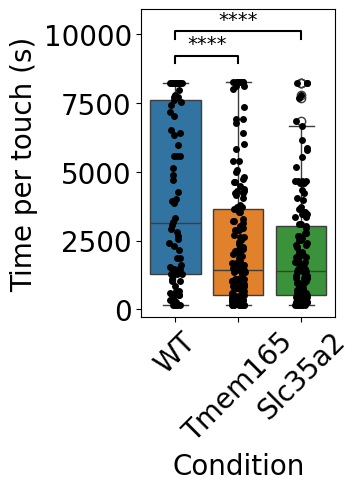

In [74]:
t1 = stats.ttest_ind(wt, tmem,equal_var=False)
t2 = stats.ttest_ind(wt, slc,equal_var=False)
# Number of touches per cell
dftouch = pd.melt(datatimes,var_name="Condition",value_name="Time")
dftouch = dftouch[dftouch['Time'].notna()]
dftouch.head()
plt.rcParams['font.size'] = 20
fig, ax = plt.subplots(figsize=(2.5,4))
plt.xticks(rotation=45)
ax = sns.boxplot(x="Condition",y="Time",hue="Condition",data=dftouch)
ax = sns.stripplot(x="Condition",y="Time",data=dftouch,color="k")
annotations = [("WT", "Tmem165", t1.pvalue), ("WT", "Slc35a2", t2.pvalue)]
starbars.draw_annotation(annotations,fontsize=14,top_margin=0.05)
plt.ylabel("Time per touch (s)")
plt.savefig('Plots/Time_per_touch.pdf',bbox_inches='tight')
plt.show()

In [42]:
df = pd.concat([dataavg,datadeath],axis=1)
wt = df[df['WT.1'].notna()]['WT']
wt1 = df[df['WT.1'].isna()]['WT']
tmem = df[df['Tmem165.1'].notna()]['Tmem165']
tmem1 = df[df['Tmem165.1'].isna()]['Tmem165']
slc = df[df['Slc35a2.1'].notna()]['Slc35a2']
slc1 = df[df['Slc35a2.1'].isna()]['Slc35a2']
data = pd.DataFrame({'WT_dead':wt,'WT_live':wt1,'Tmem165_dead':tmem,'Tmem165_live':tmem1,'Slc35a2_dead':slc,'Slc35a2_live':slc1})

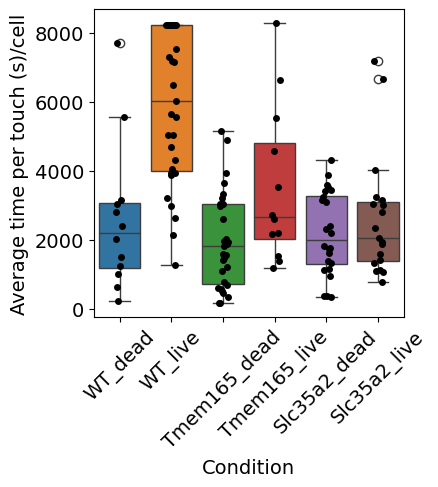

In [73]:
datalong = pd.melt(data,var_name="Condition",value_name="Time")
datalong = datalong[datalong['Time'].notna()]
datalong.head()
plt.rcParams['font.size'] = 14
fig, ax = plt.subplots(figsize=(4,4))
ax = sns.boxplot(x="Condition",y="Time",hue="Condition",data=datalong)
ax = sns.stripplot(x="Condition",y="Time",data=datalong,color="k")
#annotations = [("WT", "Tmem165", t1.pvalue), ("WT", "Slc35a2", t2.pvalue)]
#starbars.draw_annotation(annotations)
plt.xticks(rotation=45)
plt.ylabel("Average time per touch (s)/cell")
plt.savefig('Plots/Avg_time_6_groups.pdf',bbox_inches='tight')
plt.show()